# Customer Pulse: Customer Inactivity / churn Prediction 

This notebook implements the Customer Pulse concept using the [COFINFAD source](https://data.mendeley.com/datasets/mhb4zn3258/1) dataset. This dataset describes a Colombian fintech dataset and amounts in COP. These are not Ugandan shillings and results do not validate performance at any Ugandan bank.
The **Goal** is to turn the concept into a reproducible supervised-learning experiment that then can also be implemented in the uganda setting.

## Research design and important limitation

The dataset doesnot contain a customer churn/account-closure label. The existing `churn_probability` field is deliberately excluded since it may bais the outcome. Therfore we construct a **60-day future transaction-inactivity proxy**:

- Observation period: 4 January 2023 – 30 October 2023.
- Outcome period: 31 October 2023 – 29 December 2023.
- Target `1`: no transaction during the outcome period.
- Target `0`: at least one transaction during the outcome period.

This is a proxy for disengagement, **not confirmed contractual churn** however it can be used in the follow up. 
For Future work, we would need verified account-closure or customer-exit records to train and validate a true churn model for a bank.

All transaction-derived predictors are calculated using observation-period transactions. We didnot use Full-year aggregate fields and `churn_probability` as predictors.

## 1. Environment setup
Executed with Python 3.12 and pandas 2.2.3, scikit-learn 1.8.0, XGBoost 3.4.1, SHAP 0.50.0.

In [1]:
# %pip install numpy pandas scipy matplotlib seaborn scikit-learn xgboost shap joblib

In [2]:
from pathlib import Path
import joblib
from scipy.special import logit, expit
from sklearn.metrics import precision_recall_curve
from sklearn.calibration import calibration_curve
from IPython.display import display

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    roc_auc_score, average_precision_score, precision_score,
    recall_score, f1_score, accuracy_score, confusion_matrix,
    classification_report, ConfusionMatrixDisplay, RocCurveDisplay,
    PrecisionRecallDisplay, brier_score_loss
)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

RANDOM_STATE = 42
pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid")

## 2. Load the supplied dataset

The dataset contains two files, Customer and transaction files.
Placed both CSV files in the same directory as this notebook.

In [3]:
def input_file(*names):
    for directory in (Path("."), Path("data")):
        for name in names:
            if (directory / name).is_file():
                return directory / name
    raise FileNotFoundError(f"Place one of {names} next to the notebook or in data/.")

customers = pd.read_csv(input_file("customer_data.csv"),
                        dtype={"customer_id": "string"}, usecols=lambda c: c != "churn_probability")
transactions = pd.read_csv(input_file("transactions_data.csv"),
                           dtype={"customer_id": "string", "type": "category"}, parse_dates=["date"])
out = Path("outputs/customer_pulse_workflow")
out.mkdir(parents=True, exist_ok=True)
print("Loaded", len(customers), "customers and", len(transactions), "transaction events.")
display(customers.head(3), transactions.head(3))

Loaded 48723 customers and 3159157 transaction events.


,customer_id,age,gender,location,income_bracket,occupation,education_level,marital_status,household_size,acquisition_channel,customer_segment,savings_account,credit_card,personal_loan,investment_account,insurance_product,active_products,app_logins_frequency,feature_usage_diversity,bill_payment_user,auto_savings_enabled,credit_utilization_ratio,international_transactions,failed_transactions,tx_count,avg_tx_value,total_tx_volume,first_tx,last_tx,base_satisfaction,tx_satisfaction,product_satisfaction,satisfaction_score,nps_score,last_survey_date,support_tickets_count,resolved_tickets_ratio,app_store_rating,feedback_sentiment,feature_requests,complaint_topics,clv_segment,monthly_transaction_count,average_transaction_value,total_transaction_volume,transaction_frequency,last_transaction_date,preferred_transaction_type,first_transaction_date,weekend_transaction_ratio,avg_daily_transactions,customer_tenure,customer_lifetime_value
0,93716481,44,Male,"Pereira, Risaralda",Very High,Engineer,Master,Married,5,Partnership,occasional,True,True,False,False,True,1,15,3,False,False,0.17871,1,0,76,1.679872e+06,127670300,2023-01-05,2023-12-25,9.213372,0.38,0.6,5,-7,2023-12-16,1,0.0,3.5,Neutral,Budgeting tools,NaN,Gold,1.428571,6.054025e+06,60540250,0.030769,2023-12-05,Transfer,2023-01-05,0.300000,0.030769,11.633333,3.124148e+08
1,49020929,44,Male,"Cali, Valle del Cauca",Medium,Construction Worker,Bachelor,Married,2,Paid Ad,regular,True,False,False,False,False,5,30,0,True,False,NaN,1,0,10,5.445810e+06,54458100,2023-02-05,2023-12-20,6.073093,0.05,0.2,3,-46,2023-05-05,1,1.0,4.0,Positive,NaN,NaN,Bronze,1.571429,2.127414e+06,23401550,0.032934,2023-12-18,Transfer,2023-02-05,0.181818,0.032934,11.500000,1.670223e+08
2,52690950,45,Male,"Barranquilla, Atlántico",High,Construction Worker,Bachelor,Married,4,Paid Ad,inactive,True,False,False,True,True,3,4,4,True,False,NaN,1,0,10,6.403350e+05,6403350,2023-01-31,2023-12-12,8.198643,0.05,0.6,4,-29,2023-11-16,0,0.0,5.0,Positive,NaN,NaN,Gold,2.500000,3.575915e+06,35759150,0.050000,2023-10-27,Transfer,2023-01-31,0.300000,0.050000,8.766667,1.940371e+07


,customer_id,date,amount,type
0,93716481,2023-11-23,1262800,Transfer
1,93716481,2023-01-05,928900,Withdrawal
2,93716481,2023-11-05,1683100,Payment


## 3. Understanding the Data.

Did this through inspecting data types, missing values, duplicate records, date ranges, transaction types and customer coverage. This stage helps identify data quality issues before constructing features.

In [4]:
print("CUSTOMER DATA TYPES")
display(customers.dtypes.value_counts().rename_axis("dtype").to_frame("column_count"))

print("TRANSACTION DATA TYPES")
display(transactions.dtypes.value_counts().rename_axis("dtype").to_frame("column_count"))

quality = pd.DataFrame({
    "missing_count": customers.isna().sum(),
    "missing_percent": customers.isna().mean().mul(100).round(2),
    "dtype": customers.dtypes.astype(str)
}).sort_values("missing_percent", ascending=False)
display(quality)

print("Duplicate customer IDs:", customers["customer_id"].duplicated().sum())
print("Duplicate transaction rows:", transactions.duplicated().sum())
print("Transaction date range:", transactions["date"].min(), "to", transactions["date"].max())
print("Unique customers in customer file:", customers["customer_id"].nunique())
print("Unique customers in transaction file:", transactions["customer_id"].nunique())
print("Transaction customer IDs missing from customer file:",
      (~transactions["customer_id"].isin(customers["customer_id"])).sum())

CUSTOMER DATA TYPES


,column_count
dtype,
str,18
float64,14
int64,13
bool,7
string,1


TRANSACTION DATA TYPES


,column_count
dtype,
string,1
datetime64[us],1
int64,1
category,1


,missing_count,missing_percent,dtype
complaint_topics,24346,49.97,str
credit_utilization_ratio,18263,37.48,float64
feature_requests,16115,33.07,str
age,0,0.00,int64
customer_id,0,0.00,string
occupation,0,0.00,str
education_level,0,0.00,str
marital_status,0,0.00,str
household_size,0,0.00,int64
acquisition_channel,0,0.00,str


Duplicate customer IDs: 0
Duplicate transaction rows: 102
Transaction date range: 2023-01-04 00:00:00 to 2023-12-29 00:00:00
Unique customers in customer file: 48723
Unique customers in transaction file: 48723
Transaction customer IDs missing from customer file: 0


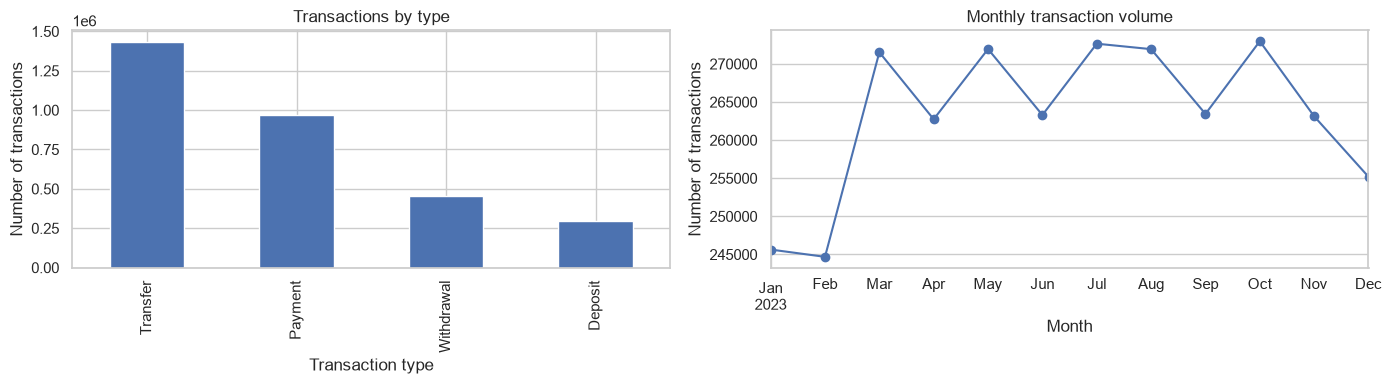

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
transactions["type"].value_counts().plot(kind="bar", ax=axes[0])
axes[0].set_title("Transactions by type")
axes[0].set_xlabel("Transaction type")
axes[0].set_ylabel("Number of transactions")

transactions["date"].dt.to_period("M").value_counts().sort_index().plot(kind="line", marker="o", ax=axes[1])
axes[1].set_title("Monthly transaction volume")
axes[1].set_xlabel("Month")
axes[1].set_ylabel("Number of transactions")
plt.tight_layout()
plt.show()

### Data Quality decisions

- `customer_id` is an just identifier, not a predictive feature.
- `churn_probability` is excluded from both predictors and target construction.
- Customer-level transaction aggregates can summarize the full year; they are excluded from the temporally constructed feature set to avoid leakage.
- The transaction event table is the source used to derive transaction dates not the `last_transaction_date` field. 
- Missing values in optional customer profile fields will be imputed inside the training pipeline, so imputation statistics are learned from training data only.

In [6]:
assert customers.customer_id.notna().all() and customers.customer_id.is_unique
assert transactions.customer_id.isin(customers.customer_id).all()
assert transactions[["date", "amount", "type"]].notna().all().all()
assert pd.api.types.is_datetime64_any_dtype(transactions.date)
assert np.isfinite(transactions.amount).all() and transactions.amount.gt(0).all()
display(transactions.amount.quantile([0, .25, .50, .75, .95, .99, 1]).rename("Amount (COP)").to_frame())

,Amount (COP)
0.00,36400.0
0.25,828550.0
0.50,1788300.0
0.75,4184700.0
0.95,14697270.0
0.99,33028806.0
1.00,689739900.0


Retained positive high-value events and report their spread. The median feature provides a measure of typical transaction value that is less sensitive to the upper tail. Repeated customer/date/amount/type tuples are retained because the ledger provides no unique event ID or time of day to identify duplicate ingestion.

## 4. Defining the observation and outcome periods

The transaction file ends on 29 December 2023. The following 60-day outcome period provides a future inactivity proxy. The cutoff is fixed before any modelling.

In [7]:
OBSERVATION_START = pd.Timestamp("2023-01-04")
OBSERVATION_END = pd.Timestamp("2023-10-30")
OUTCOME_START = pd.Timestamp("2023-10-31")
OUTCOME_END = pd.Timestamp("2023-12-29")

assert transactions["date"].min() <= OBSERVATION_START
assert transactions["date"].max() >= OUTCOME_END
assert OUTCOME_START == OBSERVATION_END + pd.Timedelta(days=1)

obs_tx = transactions.loc[
    transactions["date"].between(OBSERVATION_START, OBSERVATION_END)
].copy()

outcome_tx = transactions.loc[
    transactions["date"].between(OUTCOME_START, OUTCOME_END)
].copy()

print("Observation transactions:", len(obs_tx))
print("Outcome transactions:", len(outcome_tx))
print("Outcome period days:", (OUTCOME_END - OUTCOME_START).days + 1)

Observation transactions: 2631989
Outcome transactions: 527168
Outcome period days: 60


In [8]:
for events, start, end in [(obs_tx, OBSERVATION_START, OBSERVATION_END),
                           (outcome_tx, OUTCOME_START, OUTCOME_END)]:
    assert events.date.nunique() == (end - start).days + 1
assert obs_tx.date.max() < outcome_tx.date.min()

## 5. Constructing the target variable

A customer is labelled inactive (`1`) if they have zero transactions in the future outcome period. A customer with one or more transactions is labelled active (`0`).

This label is derived from observed future activity.

churn_proxy
Active (0)            45987
Inactive proxy (1)     2736
Name: count, dtype: int64
Proxy-positive rate: 5.62 %


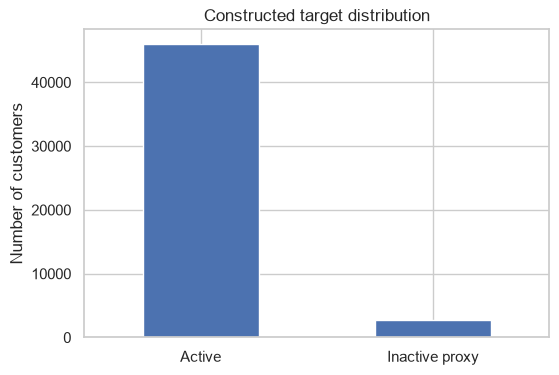

In [9]:
customer_ids = customers[["customer_id"]].drop_duplicates().copy()

future_counts = (
    outcome_tx.groupby("customer_id")
    .size()
    .rename("outcome_transaction_count")
)

target = customer_ids.merge(future_counts, on="customer_id", how="left")
target["outcome_transaction_count"] = target["outcome_transaction_count"].fillna(0).astype(int)
target["churn_proxy"] = (target["outcome_transaction_count"] == 0).astype(int)

print(target["churn_proxy"].value_counts().rename(index={0: "Active (0)", 1: "Inactive proxy (1)"}))
print("Proxy-positive rate:", round(target["churn_proxy"].mean() * 100, 2), "%")

ax = target["churn_proxy"].value_counts().sort_index().rename(
    index={0: "Active", 1: "Inactive proxy"}
).plot(kind="bar", figsize=(6, 4))
ax.set_title("Constructed target distribution")
ax.set_ylabel("Number of customers")
ax.set_xlabel("")
plt.xticks(rotation=0)
plt.show()
assert target.customer_id.is_unique and len(target) == len(customers)
assert target.outcome_transaction_count.sum() == len(outcome_tx)
assert set(target.loc[target.churn_proxy.eq(0), "customer_id"]) == set(outcome_tx.customer_id)
target.to_csv(out / "label_audit.csv", index=False)

## 6. Feature engineering from observation-period transactions

The following predictors use only transactions dated on or before 30 October 2023. Features include recency, frequency, monetary behaviour, active months, transaction-type mix, weekend activity and monthly activity trend.

In [10]:
def build_transaction_features(tx):
    tx = tx.copy()
    tx["month"] = tx["date"].dt.to_period("M").astype(str)
    tx["is_weekend"] = (tx["date"].dt.dayofweek >= 5).astype(int)

    grouped = tx.groupby("customer_id")
    features = grouped.agg(
        transaction_count=("date", "size"),
        total_transaction_amount=("amount", "sum"),
        average_transaction_amount=("amount", "mean"),
        median_transaction_amount=("amount", "median"),
        transaction_amount_std=("amount", "std"),
        minimum_transaction_amount=("amount", "min"),
        maximum_transaction_amount=("amount", "max"),
        first_observed_transaction=("date", "min"),
        last_observed_transaction=("date", "max"),
        active_months=("month", "nunique"),
        weekend_transaction_count=("is_weekend", "sum")
    )

    features["transaction_recency_days"] = (
        OBSERVATION_END - features["last_observed_transaction"]
    ).dt.days

    features["observation_span_days"] = (
        features["last_observed_transaction"] - features["first_observed_transaction"]
    ).dt.days

    features["transactions_per_active_month"] = (
        features["transaction_count"] / features["active_months"].clip(lower=1)
    )
    features["weekend_transaction_ratio"] = (
        features["weekend_transaction_count"] / features["transaction_count"].clip(lower=1)
    )

    # Transaction-type counts and proportions
    type_counts = pd.crosstab(tx["customer_id"], tx["type"])
    type_counts.columns = [
        "type_count_" + str(c).lower().replace(" ", "_") for c in type_counts.columns
    ]
    features = features.join(type_counts, how="left")

    count_cols = [c for c in type_counts.columns]
    for col in count_cols:
        ratio_col = col.replace("type_count_", "type_ratio_")
        features[ratio_col] = features[col] / features["transaction_count"].clip(lower=1)

    # Monthly transaction-count trend (slope): negative values indicate declining activity.
    all_months = pd.period_range(
        OBSERVATION_START, OBSERVATION_END, freq="M"
    ).astype(str).tolist()

    # Include zero-transaction months; otherwise a decline can be hidden.
    monthly_counts = (
        tx
          .pivot_table(index="customer_id", columns="month",
                      values="date", aggfunc="size", fill_value=0)
          .reindex(columns=all_months, fill_value=0)
    )

    x = np.arange(len(all_months), dtype=float)
    x_centered = x - x.mean()
    denominator = np.sum(x_centered ** 2)
    slopes = monthly_counts.to_numpy(dtype=float) @ x_centered / denominator
    trend = pd.Series(
        slopes, index=monthly_counts.index,
        name="monthly_transaction_count_trend"
    )
    features = features.join(trend, how="left")
    features["active_days"] = grouped.date.nunique()
    recent = tx[tx.date >= OUTCOME_START - pd.Timedelta(days=30)].groupby("customer_id")
    previous = tx[tx.date.between(OUTCOME_START - pd.Timedelta(days=60),
                                  OUTCOME_START - pd.Timedelta(days=30), inclusive="left")].groupby("customer_id")
    features["count_last_30d"] = recent.size().reindex(features.index, fill_value=0)
    features["recent_count_change"] = features.count_last_30d - previous.size().reindex(features.index, fill_value=0)

    # Remove raw date columns after deriving recency and span.
    features = features.drop(columns=[
        "first_observed_transaction", "last_observed_transaction"
    ])
    return features.reset_index()

transaction_features = build_transaction_features(obs_tx)
print("Engineered transaction feature shape:", transaction_features.shape)
display(transaction_features.head())

Engineered transaction feature shape: (48723, 26)


,customer_id,transaction_count,total_transaction_amount,average_transaction_amount,median_transaction_amount,transaction_amount_std,minimum_transaction_amount,maximum_transaction_amount,active_months,weekend_transaction_count,transaction_recency_days,observation_span_days,transactions_per_active_month,weekend_transaction_ratio,type_count_deposit,type_count_payment,type_count_transfer,type_count_withdrawal,type_ratio_deposit,type_ratio_payment,type_ratio_transfer,type_ratio_withdrawal,monthly_transaction_count_trend,active_days,count_last_30d,recent_count_change
0,10000617,7,46320100,6.617157e+06,6296950.0,2.676779e+06,3424650,11043950,5,2,13,276,1.40,0.285714,0,2,5,0,0.000000,0.285714,0.714286,0.000000,-0.054545,7,1,1
1,10003212,9,20270150,2.252239e+06,1879450.0,1.449544e+06,535600,5076800,6,2,3,282,1.50,0.222222,0,2,7,0,0.000000,0.222222,0.777778,0.000000,-0.078788,9,2,2
2,10004554,10,35759150,3.575915e+06,3278150.0,2.190858e+06,955200,7478700,4,3,3,200,2.50,0.300000,1,3,4,2,0.100000,0.300000,0.400000,0.200000,0.278788,10,4,4
3,10008981,12,16635000,1.386250e+06,996775.0,1.060574e+06,548200,4078950,8,2,10,252,1.50,0.166667,0,2,8,2,0.000000,0.166667,0.666667,0.166667,-0.060606,12,1,0
4,10011329,18,11118250,6.176806e+05,508600.0,5.192713e+05,220350,2579750,8,6,4,285,2.25,0.333333,1,6,7,4,0.055556,0.333333,0.388889,0.222222,0.060606,17,2,0


Recency will be zero when the last transaction was on 30 October. A negative monthly slope suggests declining counts and includes zero-activity months. January and October are partial calendar months. The recent-count change compares two equal windows, 1–30 September and 1–30 October, to avoid differences in month length.

## 7. Integrating customer profile information

Joined the two files by customer ID. Used acquisition channel as the only profile predictor, assuming it was recorded at onboarding. The recorded gender field will be used separately for a descriptive performance audit.

In [11]:
PROFILE_COLUMNS = ["acquisition_channel"]

profile = customers[["customer_id"] + PROFILE_COLUMNS].copy()

model_data = (
    customer_ids
    .merge(transaction_features, on="customer_id", how="left")
    .merge(profile, on="customer_id", how="left")
    .merge(target[["customer_id", "churn_proxy"]], on="customer_id", how="inner")
)

print("Final modelling dataset:", model_data.shape)
print("Missing feature values:", int(model_data.drop(columns=["customer_id", "churn_proxy"]).isna().sum().sum()))
display(model_data.head())
assert model_data.customer_id.is_unique and len(model_data) == len(customers)
assert model_data.transaction_count.sum() == len(obs_tx)
print("Customers without observation history:", model_data.transaction_count.isna().sum())

Final modelling dataset: (48723, 28)
Missing feature values: 0


,customer_id,transaction_count,total_transaction_amount,average_transaction_amount,median_transaction_amount,transaction_amount_std,minimum_transaction_amount,maximum_transaction_amount,active_months,weekend_transaction_count,transaction_recency_days,observation_span_days,transactions_per_active_month,weekend_transaction_ratio,type_count_deposit,type_count_payment,type_count_transfer,type_count_withdrawal,type_ratio_deposit,type_ratio_payment,type_ratio_transfer,type_ratio_withdrawal,monthly_transaction_count_trend,active_days,count_last_30d,recent_count_change,acquisition_channel,churn_proxy
0,93716481,64,114253400,1.785209e+06,1281875.0,1.434588e+06,370400,7068550,10,17,8,290,6.400000,0.265625,5,21,29,9,0.078125,0.328125,0.453125,0.140625,-0.230303,61,5,0,Partnership,0
1,49020929,9,50091900,5.565767e+06,4675750.0,4.376733e+06,1391700,16129100,5,2,27,240,1.800000,0.222222,1,2,4,2,0.111111,0.222222,0.444444,0.222222,-0.018182,9,1,1,Paid Ad,0
2,52690950,8,5335650,6.669562e+05,496200.0,4.536587e+05,215400,1663650,7,2,20,252,1.142857,0.250000,1,3,4,0,0.125000,0.375000,0.500000,0.000000,0.060606,8,1,-1,Paid Ad,0
3,23199751,19,12858600,6.767684e+05,621600.0,3.087273e+05,163600,1314900,9,7,9,284,2.111111,0.368421,5,5,4,5,0.263158,0.263158,0.210526,0.263158,0.115152,18,2,0,Referral,0
4,61997066,15,245921000,1.639473e+07,11438500.0,1.227130e+07,3150200,42242000,9,8,8,290,1.666667,0.533333,1,5,7,2,0.066667,0.333333,0.466667,0.133333,-0.151515,15,1,1,Paid Ad,0


Customers without observation history: 0


## 8. Preparing X and y; split the data

The customer ID is removed from predictors. The split is stratified so that the rare inactive class is represented in training, validation and test partitions.

- 70% training
- 15% validation
- 15% test

The validation set is used for threshold selection and model comparison. The test set is reserved for final evaluation.

Within validation, reserve half of the customers for probability calibration and half for model and threshold selection. Keep the original seed of 42.

In [12]:
X = model_data.drop(columns=["customer_id", "churn_proxy"])
y = model_data["churn_proxy"].astype(int)

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=RANDOM_STATE
)
X_valid, X_test, y_valid, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=RANDOM_STATE
)

print("Train:", X_train.shape, "positive rate:", round(y_train.mean(), 4))
print("Validation:", X_valid.shape, "positive rate:", round(y_valid.mean(), 4))
print("Test:", X_test.shape, "positive rate:", round(y_test.mean(), 4))
cal_idx, select_idx = train_test_split(np.arange(len(y_valid)), test_size=0.5,
                                       stratify=y_valid.to_numpy(), random_state=RANDOM_STATE)
assert len(set(X_train.index) | set(X_valid.index) | set(X_test.index)) == len(model_data)
assert set(cal_idx).isdisjoint(select_idx)
display(pd.DataFrame({k: {"customers": len(v), "inactive": int(v.sum()), "rate": v.mean()}
                      for k, v in {"train": y_train, "calibration": y_valid.iloc[cal_idx],
                                   "selection": y_valid.iloc[select_idx], "test": y_test}.items()}).T)
display(X_train.groupby(y_train)[["transaction_count", "transaction_recency_days",
                                  "count_last_30d", "monthly_transaction_count_trend"]].median())

Train: (34106, 26) positive rate: 0.0561
Validation: (7308, 26) positive rate: 0.0561
Test: (7309, 26) positive rate: 0.0562


,customers,inactive,rate
train,34106.0,1915.0,0.056148
calibration,3654.0,205.0,0.056103
selection,3654.0,205.0,0.056103
test,7309.0,411.0,0.056232


,transaction_count,transaction_recency_days,count_last_30d,monthly_transaction_count_trend
churn_proxy,,,,
0,16.0,10.0,2.0,0.018182
1,12.0,16.0,1.0,0.012121


## 9. Preprocessing pipeline

Numeric variables are median-imputed and standardized for Logistic Regression. Categorical variables are most-frequent imputed and one-hot encoded. The same preprocessing design is used consistently across the three models.

Preprocessing is fitted only on the training set, preventing information from validation/test data from influencing imputation or encoding.

In [13]:
numeric_features = X_train.select_dtypes(include=["number", "bool"]).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=["number", "bool"]).columns.tolist()

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

X_train_processed = preprocessor.fit_transform(X_train)
X_valid_processed = preprocessor.transform(X_valid)
X_test_processed = preprocessor.transform(X_test)

feature_names = preprocessor.get_feature_names_out()

print("Processed training matrix:", X_train_processed.shape)
print("Number of model features:", len(feature_names))

Processed training matrix: (34106, 29)
Number of model features: 29


## 10. Model training

Used Logistic Regression as the baseline, Random Forest as an additional tree-based comparison and XGBoost.

The target is imbalanced, so class weighting is used for Logistic Regression and Random Forest. XGBoost uses `scale_pos_weight`, calculated from the training labels only.

The random forest uses 160 trees, maximum depth 12 and a minimum of eight customers per leaf. These fixed settings limit computation and avoid estimates from very small leaves. Hyperparameters are prespecified for this comparison.

In [14]:
positive = int(y_train.sum())
negative = int((y_train == 0).sum())
scale_pos_weight = negative / max(positive, 1)
print("XGBoost scale_pos_weight:", round(scale_pos_weight, 2))

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=160, max_depth=12, min_samples_leaf=8,
        class_weight="balanced_subsample",
        n_jobs=2, random_state=RANDOM_STATE
    ),
    "XGBoost": XGBClassifier(
        n_estimators=500, max_depth=4, learning_rate=0.04,
        subsample=0.85, colsample_bytree=0.85,
        min_child_weight=3, reg_lambda=2,
        objective="binary:logistic", eval_metric="aucpr",
        scale_pos_weight=scale_pos_weight,
        tree_method="hist", n_jobs=2,
        random_state=RANDOM_STATE
    )
}

fitted_models = {}
validation_probabilities = {}

for name, model in models.items():
    model.fit(X_train_processed, y_train)
    fitted_models[name] = model
    validation_probabilities[name] = model.predict_proba(X_valid_processed)[:, 1]
    print(name, "trained.")

XGBoost scale_pos_weight: 16.81
Logistic Regression trained.
Random Forest trained.
XGBoost trained.


## 11. Calibrating scores and choose a model before testing

Class weighting changes the meaning of the raw score. For each model, fitted a sigmoid mapping from its raw log-odds to observed inactivity using only the calibration subset. On the separate selection subset, chose the family with the highest average precision (AP). Chose each model's cutoff by maximum F1. This gives precision and recall equal weight for the classification rule.

In [15]:
def log_odds(scores):
    return logit(np.clip(np.asarray(scores, dtype=float), 1e-7, 1-1e-7)).reshape(-1, 1)

calibrators, selected_thresholds, validation_ap = {}, {}, {}
for name, raw in validation_probabilities.items():
    mapper = LogisticRegression(C=1e4, max_iter=500).fit(log_odds(raw[cal_idx]), y_valid.iloc[cal_idx])
    calibrators[name] = mapper
    p = mapper.predict_proba(log_odds(raw[select_idx]))[:, 1]
    precision, recall, cutoffs = precision_recall_curve(y_valid.iloc[select_idx], p)
    f1 = 2 * precision[:-1] * recall[:-1] / np.maximum(precision[:-1] + recall[:-1], 1e-12)
    selected_thresholds[name] = float(cutoffs[np.argmax(f1)])
    validation_ap[name] = average_precision_score(y_valid.iloc[select_idx], p)
selection = pd.DataFrame({"Selection AP": validation_ap, "F1 threshold": selected_thresholds})
display(selection.sort_values("Selection AP", ascending=False))
best_model_name = selection["Selection AP"].idxmax()
best_model = fitted_models[best_model_name]
best_threshold = selected_thresholds[best_model_name]
print("Selected model:", best_model_name)

,Selection AP,F1 threshold
Random Forest,0.181111,0.112879
XGBoost,0.162632,0.119042
Logistic Regression,0.086516,0.065819


Selected model: Random Forest


## 12. Model evaluation and comparison on the untouched test set

ROC-AUC measures ranking discrimination, while average precision (AP) is especially useful when the positive class is rare. Precision and recall describe the selected operating threshold. Specificity measures the proportion of retained customers correctly identified as retained. Brier score measures probability prediction error (lower is better).

In [16]:
def calculate_metrics(y_true, probabilities, threshold):
    predictions = (probabilities >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, predictions, labels=[0, 1]).ravel()
    return {
        "ROC-AUC": roc_auc_score(y_true, probabilities),
        "Average Precision": average_precision_score(y_true, probabilities),
        "Precision": precision_score(y_true, predictions, zero_division=0),
        "Recall": recall_score(y_true, predictions, zero_division=0),
        "F1": f1_score(y_true, predictions, zero_division=0),
        "Specificity": tn / (tn + fp) if (tn + fp) else 0,
        "Brier Score": brier_score_loss(y_true, probabilities),
        "Threshold": threshold
    }

test_probabilities = {}
results = []

for name, model in fitted_models.items():
    raw = model.predict_proba(X_test_processed)[:, 1]
    probs = calibrators[name].predict_proba(log_odds(raw))[:, 1]
    test_probabilities[name] = probs
    results.append({
        "Model": name,
        **calculate_metrics(y_test, probs, selected_thresholds[name])
    })

prior = float(y_train.mean())
results.append({"Model": "Training prevalence", **calculate_metrics(y_test, np.full(len(y_test), prior), prior)})
comparison = pd.DataFrame(results).set_index("Model").sort_values(
    "Average Precision", ascending=False
)
display(comparison.round(4))
comparison.to_csv(out / "test_comparison.csv")
best_test_probs = test_probabilities[best_model_name]

,ROC-AUC,Average Precision,Precision,Recall,F1,Specificity,Brier Score,Threshold
Model,,,,,,,,
Random Forest,0.8262,0.1711,0.1517,0.6253,0.2442,0.7917,0.0489,0.1129
XGBoost,0.8195,0.1564,0.1541,0.5766,0.2432,0.8114,0.0492,0.1190
Logistic Regression,0.6856,0.0800,0.0958,0.7762,0.1706,0.5636,0.0519,0.0658
Training prevalence,0.5000,0.0562,0.0562,1.0000,0.1065,0.0000,0.0531,0.0561


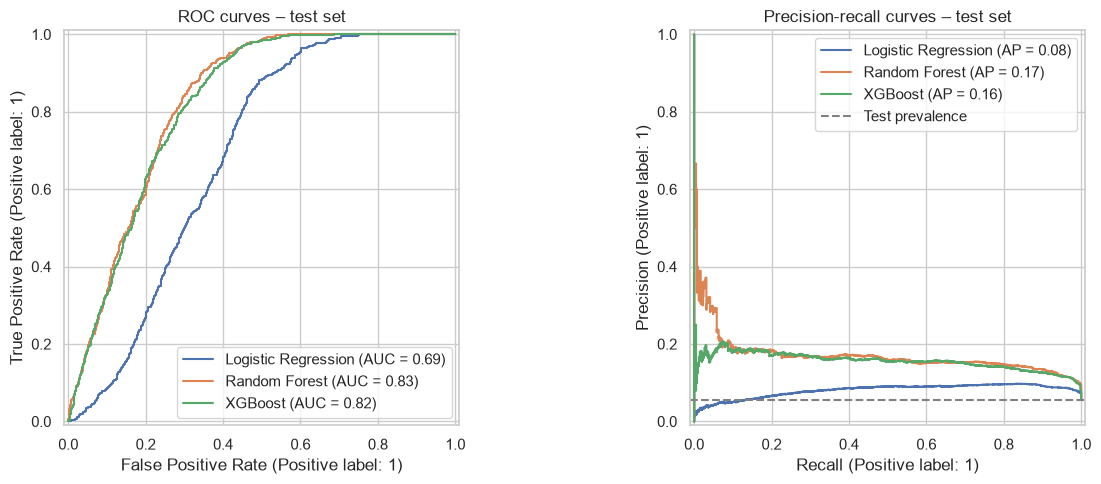

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name, probs in test_probabilities.items():
    RocCurveDisplay.from_predictions(y_test, probs, name=name, ax=axes[0])
    PrecisionRecallDisplay.from_predictions(y_test, probs, name=name, ax=axes[1])

axes[1].axhline(y_test.mean(), color="grey", ls="--", label="Test prevalence")
axes[1].legend()
axes[0].set_title("ROC curves – test set")
axes[1].set_title("Precision-recall curves – test set")
plt.tight_layout()
plt.show()

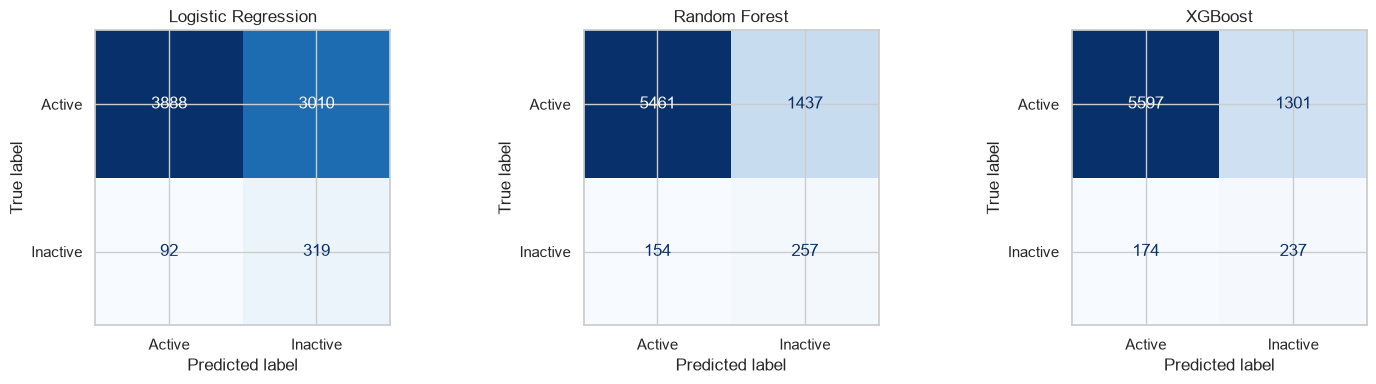

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, probs) in zip(axes, test_probabilities.items()):
    preds = (probs >= selected_thresholds[name]).astype(int)
    ConfusionMatrixDisplay.from_predictions(
        y_test, preds, display_labels=["Active", "Inactive"],
        cmap="Blues", colorbar=False, ax=ax
    )
    ax.set_title(name)
plt.tight_layout()
plt.show()

### Calibration and outreach workload

Compareing the selected model before and after calibration. Each point groups a tenth of the test scores, so the diagonal represents agreement between predicted and observed inactivity. For a team able to contact 10% of customers, we can rank the test records using the frozen score and count the true inactive customers reached.

Raw Brier score: 0.14391
Calibrated Brier score: 0.04894


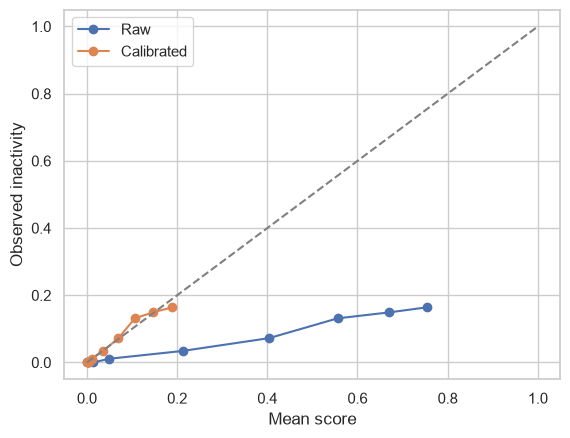

F1 threshold: 1,694 reviews, 257 inactive, 1437 active; precision 15.2%, recall 62.5%.
Top 10%: 730 reviews, 120 inactive, 610 active; precision 16.4%, recall 29.2%.


In [19]:
raw_test = best_model.predict_proba(X_test_processed)[:, 1]
for label, scores in [("Raw", raw_test), ("Calibrated", best_test_probs)]:
    observed, predicted = calibration_curve(y_test, scores, n_bins=10, strategy="quantile")
    plt.plot(predicted, observed, "o-", label=label)
    print(label, "Brier score:", round(brier_score_loss(y_test, scores), 5))
plt.plot([0,1], [0,1], "--", color="grey")
plt.xlabel("Mean score"); plt.ylabel("Observed inactivity"); plt.legend(); plt.show()

test_cases = model_data.loc[X_test.index, ["customer_id", "churn_proxy"]].copy()
test_cases["score"] = best_test_probs
ordered = test_cases.sort_values(["score", "customer_id"], ascending=[False, True])
for label, queue in [("F1 threshold", ordered[ordered.score >= best_threshold]),
                     ("Top 10%", ordered.head(len(ordered)//10))]:
    hits = int(queue.churn_proxy.sum())
    print(f"{label}: {len(queue):,} reviews, {hits} inactive, {len(queue)-hits} active; "
          f"precision {hits/max(1,len(queue)):.1%}, recall {hits/y_test.sum():.1%}.")

### Dataset coverage and subgroup checks

Examining its minimum transactions per customer as a retrospective diagnostic. If all listed customers must reach a minimum, customers below that number in October necessarily transact later in this file. Also inspected precision and recall across recorded gender groups, with denominators. 

In [20]:
total_by_customer = transactions.groupby("customer_id").size().reindex(target.customer_id, fill_value=0)
floor = int(total_by_customer.min())
below = model_data.transaction_count.fillna(0).lt(floor)
print(f"Minimum combined-period count: {floor}. Customers below it by October 30: {below.sum():,}; "
      f"subsequently inactive: {model_data.loc[below, 'churn_proxy'].sum()}.")
audit = test_cases.merge(customers[["customer_id", "gender"]], on="customer_id", validate="one_to_one")
group_rows = []
for group, part in audit.groupby("gender", dropna=False):
    flag = part.score >= best_threshold
    group_rows.append({"group": group, "customers": len(part), "inactive": part.churn_proxy.sum(),
                       "flagged": flag.sum(), "precision": precision_score(part.churn_proxy, flag, zero_division=0),
                       "recall": recall_score(part.churn_proxy, flag, zero_division=0)})
display(pd.DataFrame(group_rows))

Minimum combined-period count: 10. Customers below it by October 30: 8,203; subsequently inactive: 0.


,group,customers,inactive,flagged,precision,recall
0,Female,3626,197,843,0.148280,0.634518
1,Male,3527,206,805,0.155280,0.606796
2,Other,156,8,46,0.152174,0.875000


## 13. Explaining the validation-selected model using SHAP

Using a random sample of test customers for the global summary. Added the 25 highest-ranked test customers for individual reviews. Only the random sample contributes to the global ranking. Selected the base classifier and then applied its fitted calibration mapping to verify the final exported score. Features that move a score are associations. They cannot establish a cause of disengagement.

In [21]:
import shap
from xgboost import DMatrix
from scipy import sparse
rng = np.random.default_rng(RANDOM_STATE)
global_ids = rng.choice(len(X_test), min(512, len(X_test)), replace=False)
review_ids = X_test.index.get_indexer(ordered.head(25).index)
ids = np.unique(np.r_[global_ids, review_ids])
def dense(x):
    return x.toarray() if sparse.issparse(x) else np.asarray(x)
Z = dense(X_test_processed[ids])
if best_model_name == "XGBoost":
    terms = best_model.get_booster().predict(DMatrix(Z), pred_contribs=True)
    values, bases = terms[:, :-1], terms[:, -1]
    unit = "raw log-odds"
elif best_model_name == "Random Forest":
    explanation = shap.TreeExplainer(best_model)(Z)
    values, bases = explanation.values[:, :, 1], explanation.base_values[:, 1]
    unit = "raw probability"
else:
    background = dense(X_train_processed[rng.choice(len(y_train), 128, replace=False)])
    explainer = shap.LinearExplainer(best_model, shap.maskers.Independent(background, max_samples=128))
    explanation = explainer(Z)
    values, bases = explanation.values, explanation.base_values
    unit = "raw log-odds"

reconstructed = bases + values.sum(axis=1)
raw_from_shap = expit(reconstructed) if unit == "raw log-odds" else reconstructed
np.testing.assert_allclose(raw_from_shap, raw_test[ids], atol=2e-5)
calibrated_from_shap = calibrators[best_model_name].predict_proba(log_odds(raw_from_shap))[:, 1]
np.testing.assert_allclose(calibrated_from_shap, best_test_probs[ids], atol=2e-5)
global_rows = np.searchsorted(ids, global_ids)
shap_values, X_explain = values[global_rows], Z[global_rows]
importance = pd.Series(np.abs(shap_values).mean(axis=0), index=feature_names).sort_values(ascending=False)
print(f"Verified {len(ids)} explanations on the {unit} scale.")
display(importance.head(8).rename("mean absolute SHAP contribution").to_frame())

Verified 536 explanations on the raw probability scale.


,mean absolute SHAP contribution
num__transaction_count,0.090856
num__active_days,0.081228
num__transactions_per_active_month,0.035479
num__type_count_transfer,0.028515
num__active_months,0.023282
num__type_count_payment,0.017027
num__type_count_withdrawal,0.011629
num__weekend_transaction_count,0.011159


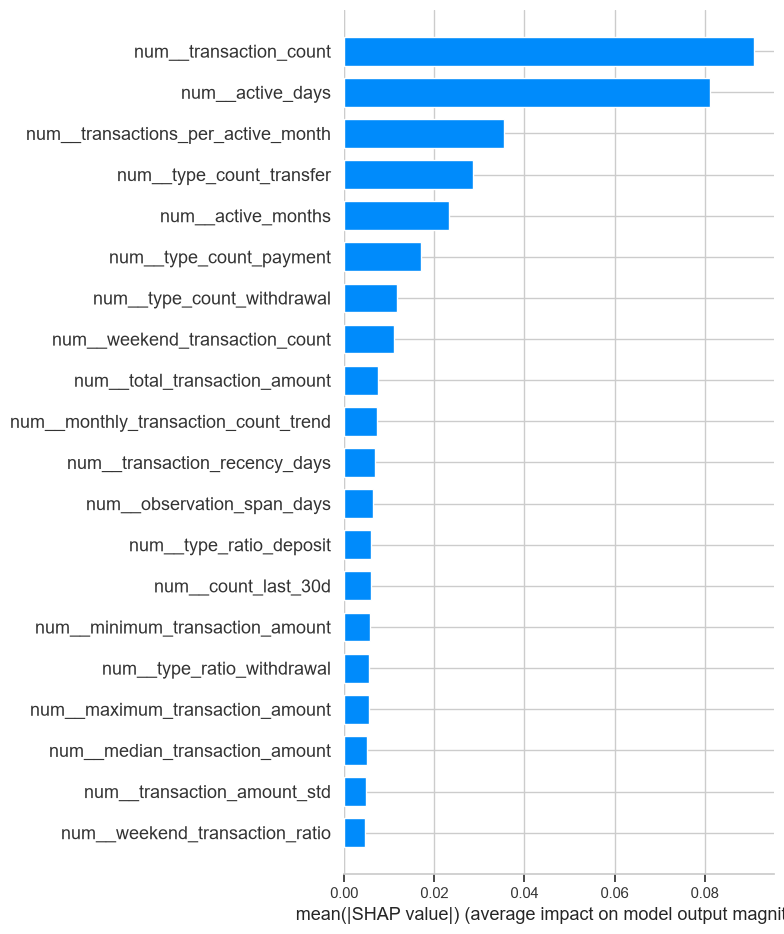

In [22]:
shap.summary_plot(
    shap_values,
    X_explain,
    feature_names=feature_names,
    plot_type="bar",
    max_display=20,
    show=True
)

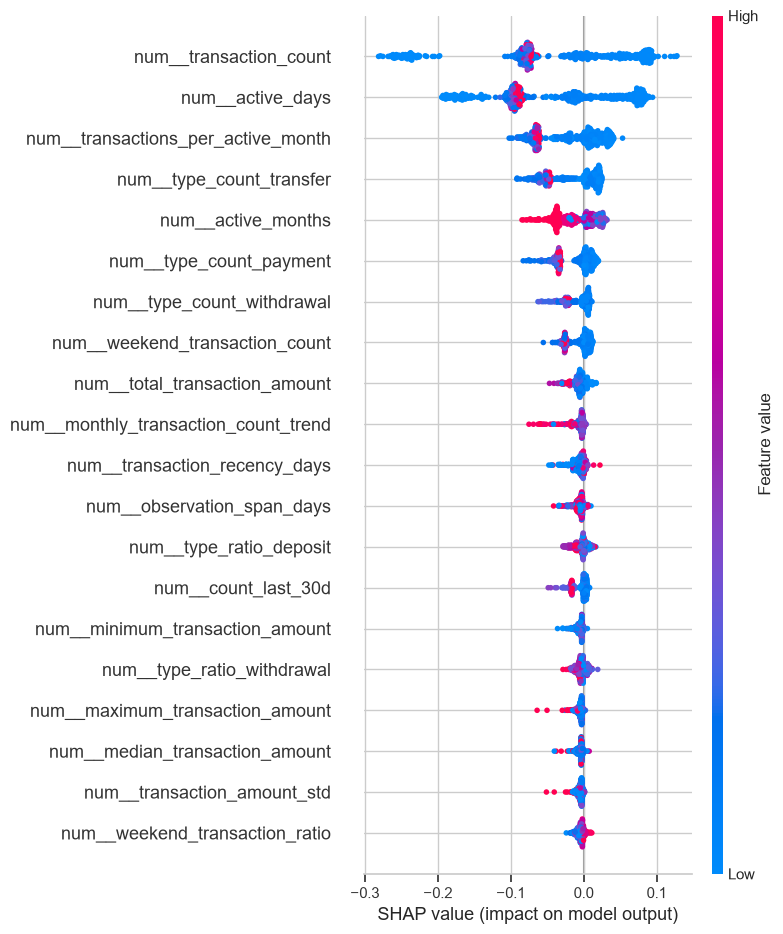

In [23]:
shap.summary_plot(
    shap_values,
    X_explain,
    feature_names=feature_names,
    max_display=20,
    show=True
)

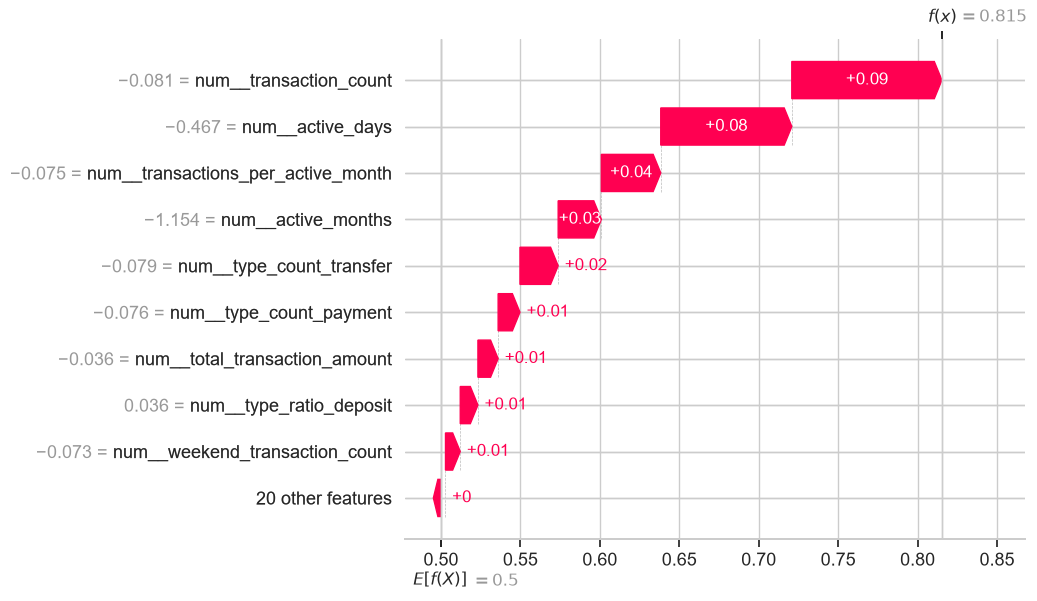

Base classifier score 81.5%; calibrated inactivity score 23.4%


,feature,signed effect
0,num__transaction_count,0.094486
1,num__active_days,0.082479
2,num__transactions_per_active_month,0.037384
3,num__active_months,0.027181
4,num__type_count_transfer,0.024041


Waterfall feature values use the model's standardized or one-hot encoded scale.


,original units
transaction_count,10
total_transaction_amount,11401250
average_transaction_amount,1140125.0
median_transaction_amount,1111250.0
transaction_amount_std,380587.194893
minimum_transaction_amount,524900
maximum_transaction_amount,1836250
active_months,6
weekend_transaction_count,4
transaction_recency_days,16


In [24]:
local = np.searchsorted(ids, review_ids[0])
case = shap.Explanation(values=values[local], base_values=float(bases[local]), data=Z[local], feature_names=feature_names)
shap.plots.waterfall(case, max_display=10, show=False)
plt.show()
print(f"Base classifier score {raw_test[review_ids[0]]:.1%}; calibrated inactivity score {best_test_probs[review_ids[0]]:.1%}")
top_features = np.argsort(np.abs(values[local]))[::-1][:5]
display(pd.DataFrame({"feature": feature_names[top_features], "signed effect": values[local, top_features]}))
print("Waterfall feature values use the model's standardized or one-hot encoded scale.")
display(X_test.iloc[[review_ids[0]]].T.rename(columns={X_test.index[review_ids[0]]:"original units"}))

## 14. Customer risk categorization and retention review

High begins at the frozen validation F1 cutoff. Medium begins at half that cutoff as an illustrative review tier.

In [25]:
all_raw = best_model.predict_proba(preprocessor.transform(X))[:, 1]
all_probabilities = calibrators[best_model_name].predict_proba(log_odds(all_raw))[:, 1]
risk_output = model_data[["customer_id"]].copy()
risk_output["inactivity_probability"] = all_probabilities
risk_output["risk_category"] = np.select(
    [all_probabilities >= best_threshold, all_probabilities >= best_threshold/2],
    ["High Risk", "Medium Risk"], default="Low Risk")
risk_output["split"] = "training"
risk_output.loc[X_valid.index, "split"] = "validation"
risk_output.loc[X_test.index, "split"] = "test"
risk_output["as_of"] = OUTCOME_START.date()
band_audit = risk_output.loc[X_test.index].assign(observed=y_test)
display(band_audit.groupby("risk_category").agg(customers=("observed","size"),
        mean_score=("inactivity_probability","mean"), observed_inactivity=("observed","mean")))
assert risk_output.customer_id.is_unique
np.testing.assert_allclose(risk_output.loc[X_test.index, "inactivity_probability"], best_test_probs)

,customers,mean_score,observed_inactivity
risk_category,,,
High Risk,1694,0.161163,0.151712
Low Risk,4450,0.009337,0.008315
Medium Risk,1165,0.083654,0.100429


In [26]:
review = ordered.head(25)[["customer_id", "score"]].copy()
drivers, suggestions = [], []
for row in np.searchsorted(ids, review_ids):
    effect = values[row]
    driver = feature_names[effect.argmax()] if effect.max() > 0 else "No positive contributor"
    drivers.append(driver)
    if "amount" in driver:
        suggestions.append("Review the customer's usual transaction values before offering a check-in.")
    elif "count" in driver or "recency" in driver or "active" in driver:
        suggestions.append("Compare recent activity with the customer's usual frequency and ask about interruptions.")
    else:
        suggestions.append("Review the customer's transaction history and contact preferences.")
review["largest_positive_driver"] = drivers
review["suggested_follow_up"] = suggestions
review.to_csv(out / "retention_review_queue.csv", index=False)
risk_output.to_csv(out / "customer_pulse_risk_predictions.csv", index=False)
joblib.dump({"preprocessor": preprocessor, "model": best_model, "name": best_model_name,
             "calibrator": calibrators[best_model_name], "calibrator_input": "logit(raw score clipped to [1e-7, 1-1e-7])",
             "feature_order": list(X.columns), "threshold": best_threshold,
             "medium_threshold": best_threshold / 2}, out / "customer_pulse_model.joblib", compress=3)
display(review.drop(columns="customer_id").head(5))
print("Outputs:", out)

,score,largest_positive_driver,suggested_follow_up
15020,0.233552,num__transaction_count,Compare recent activity with the customer's us...
7823,0.233545,num__transaction_count,Compare recent activity with the customer's us...
32800,0.230940,num__transaction_count,Compare recent activity with the customer's us...
26977,0.229630,num__transaction_count,Compare recent activity with the customer's us...
33615,0.229524,num__transaction_count,Compare recent activity with the customer's us...


Outputs: outputs\customer_pulse_workflow


## 15. Interpreting the results

In [27]:
r = comparison.loc[best_model_name]
positive_count = int(y_test.sum())
hits = int(((best_test_probs >= best_threshold) & (y_test.to_numpy() == 1)).sum())
print(f"{best_model_name} led on selection AP ({validation_ap[best_model_name]:.3f}). "
      f"On {len(y_test):,} held-out customers, AP was {r['Average Precision']:.3f} against "
      f"a prevalence baseline of {y_test.mean():.3f}.")
print(f"The frozen cutoff ({best_threshold:.3f}) identified {hits} of {positive_count} inactive customers "
      f"with precision {r['Precision']:.1%}. The leading SHAP feature was {importance.index[0]}.")

Random Forest led on selection AP (0.181). On 7,309 held-out customers, AP was 0.171 against a prevalence baseline of 0.056.
The frozen cutoff (0.113) identified 257 of 411 inactive customers with precision 15.2%. The leading SHAP feature was num__transaction_count.


**Results:** 
Random forest had the highest validation AP. On the test customers, its AP of 0.171 compares with 0.056 for a constant score; its ROC-AUC was 0.826. At the selected cutoff it captured 257 of 411 inactive customers.

Calibration reduced the forest’s test Brier score from 0.144 to 0.049. The highest-ranked example in the review queue illustrates the difference: its raw forest score was 81.5%, and its calibrated estimate was 23.4%. A high review priority can still mean that continued activity is the more likely outcome.

The ranking supports a retrospective retention-review experiment. The 10-transaction minimum in this ledger limits what can be inferred about customers with very little history. A strong SHAP contribution from transaction count can partly reflect who appears in this dataset. A customer who continued transacting is recorded as active regardless of dissatisfaction or plans to leave.

## 16. Future Work

1. Obtain a bank roster defined at scoring time and verify account closures separately from inactivity. Collect time-stamped app sessions, NPS responses, ticket resolutions and product changes so historical features reflect information actually available then.
2. Score a later cohort, wait for 60 complete days, and compare AP, calibration and recall at the same outreach capacity. Report subgroup sample sizes alongside metrics.